In [8]:
# generate random points

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
%matplotlib inline

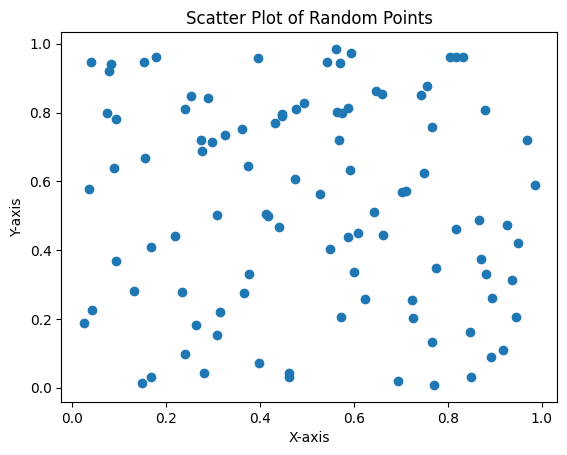

In [3]:
x = np.random.rand(100)
y = np.random.rand(100)

plt.scatter(x,y)
plt.title("Scatter Plot of Random Points")
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.show()

Plot the density of a 2D Gaussian Distribution

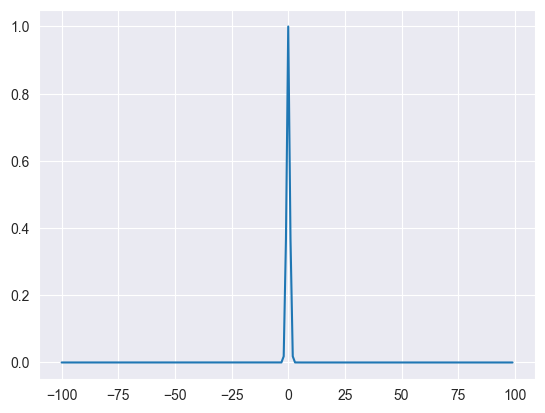

In [3]:
def my_dist(x):
    return np.exp(-x ** 2)

x = np.arange(-100, 100)
p = my_dist(x)
plt.plot(x, p)
plt.show()

In [ ]:
mu = [0,1]
sigma = 73.10

In [ ]:
# calculate the z-transform
z1 = ( x1 - mu ) / sigma
z2 = ( x2 - mu ) / sigma

In [ ]:
x = np.arange(z1, z2, 0.001) # range of x in spec
x_all = np.arange(-10, 10, 0.001) # entire range of x, both in and out of spec
# mean = 0, stddev = 1, since Z-transform was calculated
y = norm.pdf(x,0,1)
y2 = norm.pdf(x_all,0,1)

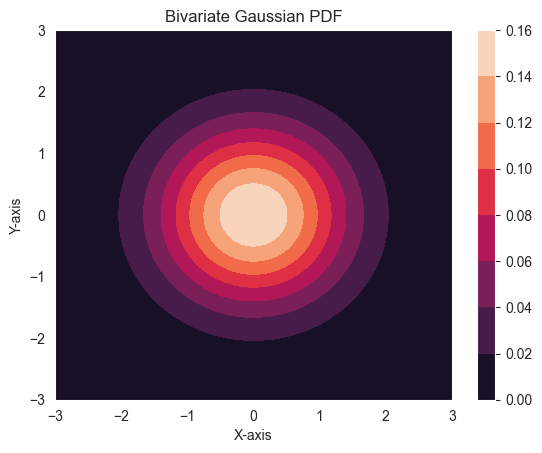

In [7]:
x = np.linspace(-4, 4, 1000)
plt.plot(x, norm.pdf(x), 'b-', label='Normal Distribution')
plt.xlabel('X')
plt.ylabel('Probability Density')
plt.legend()
plt.grid(True)
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/user-data/outputs/gaussian_2d.png'

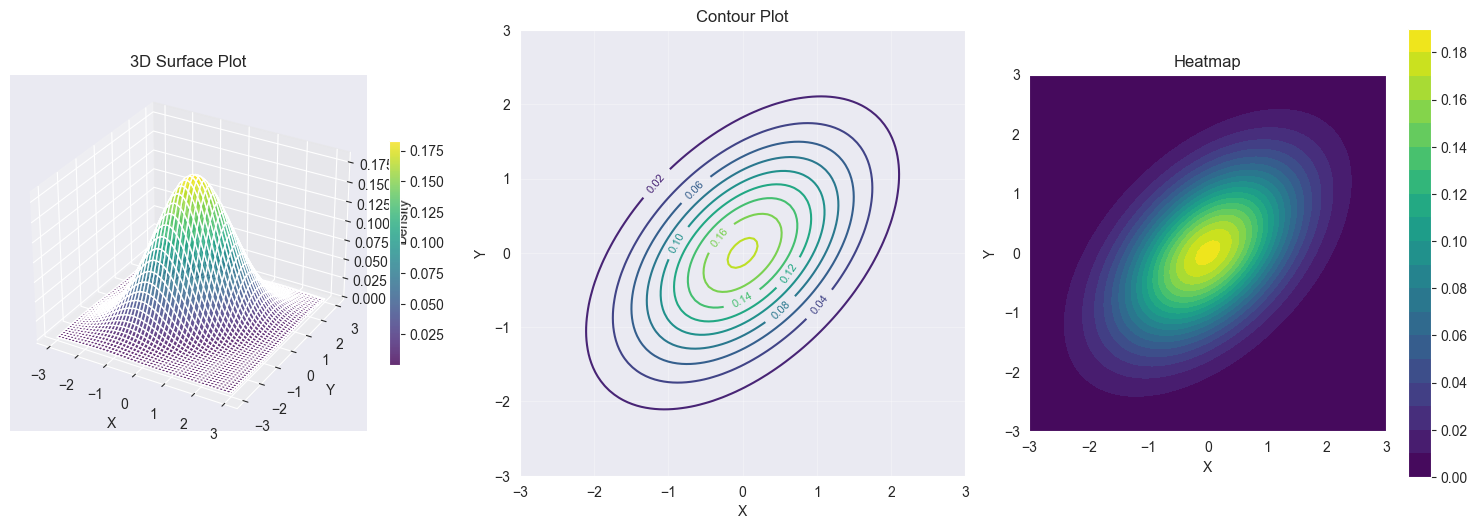

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D

# Define the parameters of the 2D Gaussian
mu = np.array([0, 0])  # Mean vector
Sigma = np.array([[1, 0.5],
                  [0.5, 1]])  # Covariance matrix

# Create a grid of points
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)

# Stack X and Y into a position array
pos = np.dstack((X, Y))

# Calculate the multivariate Gaussian density
def multivariate_gaussian(pos, mu, Sigma):
    """Calculate multivariate Gaussian probability density."""
    n = mu.shape[0]
    Sigma_det = np.linalg.det(Sigma)
    Sigma_inv = np.linalg.inv(Sigma)
    N = np.sqrt((2*np.pi)**n * Sigma_det)

    # Calculate the exponent for each point
    fac = np.einsum('...k,kl,...l->...', pos-mu, Sigma_inv, pos-mu)

    return np.exp(-fac / 2) / N

# Calculate the density
Z = multivariate_gaussian(pos, mu, Sigma)

# Create figure with subplots
fig = plt.figure(figsize=(15, 5))

# 1. 3D surface plot
ax1 = fig.add_subplot(131, projection='3d')
surf = ax1.plot_surface(X, Y, Z, cmap=cm.viridis, alpha=0.8)
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Density')
ax1.set_title('3D Surface Plot')
fig.colorbar(surf, ax=ax1, shrink=0.5)

# 2. Contour plot
ax2 = fig.add_subplot(132)
contour = ax2.contour(X, Y, Z, levels=10, cmap=cm.viridis)
ax2.clabel(contour, inline=True, fontsize=8)
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_title('Contour Plot')
ax2.set_aspect('equal')
ax2.grid(True, alpha=0.3)

# 3. Filled contour plot (heatmap)
ax3 = fig.add_subplot(133)
contourf = ax3.contourf(X, Y, Z, levels=20, cmap=cm.viridis)
ax3.set_xlabel('X')
ax3.set_ylabel('Y')
ax3.set_title('Heatmap')
ax3.set_aspect('equal')
fig.colorbar(contourf, ax=ax3)

plt.tight_layout()
plt.savefig('/mnt/user-data/outputs/gaussian_2d.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Mean vector μ = {mu}")
print(f"Covariance matrix Σ =\n{Sigma}")